In [107]:
import math
import numpy as np
import matplotlib.pyplot as g
import torch
from  graphviz import Digraph
%matplotlib inline

In [122]:
class Scalar:
    # Properties initialize Karnyasathi constructor (CTOR) asto 
    # CTOR is a special function
    # () = Tuple = list of numbers that you cannot change once assigned
    
    
    def __init__(self, value, label, oprt = '', children = ()):
        # self = Jyane he function call kele ahe to/ti
        self.value = value
        self.label = label
        self.oprt  = oprt
        self.children = children
        self.der = 0.0
        self._backward = lambda: None


    def __add__(self, other):
        out = Scalar(self.value + other.value, '', oprt='+', children=(self, other))

        # for back propagation
        def _backward():
            # Addition madhe
            # derivative of output will propagate to both of its operands
            # out = self + other
            # tar, out cha derivative self ani other kade propagate honar ahe
            self.der = 1.0 * out.der # 1.0 is local derivative of x in y = z + x (dy/dx = 1)
            other.der = 1.0 * out.der

        # function assignment
        out._backward = _backward

        return out

    def __mul__(self, other):
        out = Scalar(self.value * other.value, '', oprt='*', children=(self, other))

        def _backward():
            self.der = other.value * out.der  # y = 3 * x =>  dy/dx = 3;  c = a * b then dc/da = b
            other.der = self.value * out.der

        out._backward = _backward

        return out

        # for back propagation

    def relu(self):
        # if value is negative, makes it 0
        # else keep value as-is
        out =  Scalar(0 if self.value < 0 else self.value, '', oprt = 'ReLU', children=(self,))

        def _backward():
            self.der = (out.value > 0) * out.der

        out._backward = _backward
        return out

    def backward(self):
        '''
        What should it do ?
        '''
        visited = set() # nodes from trace function
        topo = list()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v.children:
                    build_topo(child)

                topo.append(v)

        build_topo(self) # jyane call kela tithun start kara

        self.der = 1.0 # dL/dL = 1.0
        for v in reversed(topo):
            v._backward()
            

In [123]:
def test_topo(root):
    visited = set() # nodes from trace function
    topo = list()
    def build_topo(v):
        if v not in visited:
            visited.add(v)
            for child in v.children:
                build_topo(child)

            topo.append(v)

    build_topo(root) # jyane call kela tithun start kara

    for v in reversed(topo):
        print(v.label)

trace(L)
        

({<__main__.Scalar at 0x1134996a0>,
  <__main__.Scalar at 0x1142c0b90>},
 {(<__main__.Scalar at 0x1134996a0>, <__main__.Scalar at 0x1140add00>),
  (<__main__.Scalar at 0x113889d90>, <__main__.Scalar at 0x1140add00>),
  (<__main__.Scalar at 0x1138bc640>, <__main__.Scalar at 0x1134996a0>),
  (<__main__.Scalar at 0x1138bd220>, <__main__.Scalar at 0x113dbfc50>),
  (<__main__.Scalar at 0x113b64830>, <__main__.Scalar at 0x113889d90>),
  (<__main__.Scalar at 0x113dbfc50>, <__main__.Scalar at 0x113dbfe50>),
  (<__main__.Scalar at 0x1140add00>, <__main__.Scalar at 0x113dbfc50>),
  (<__main__.Scalar at 0x1142c0a50>, <__main__.Scalar at 0x1134996a0>),
  (<__main__.Scalar at 0x1142c0b90>, <__main__.Scalar at 0x113889d90>)})

In [124]:

def trace(root):
    # nodes will act as visited array
    nodes = set() # Expression Graph che nodes 
    edges = set() # Expression Graph chya edges

    def build(v):
        if v not in nodes:
            nodes.add(v)


            for child in v.children:
                edges.add((child,v))
                build(child)

    build(root)
    return nodes, edges
    
class MermaidGraph:
    """Wraps Mermaid source so Jupyter renders it inline, like a graphviz Digraph."""
    def __init__(self, source):
        self.source = source

    def _repr_mimebundle_(self, include=None, exclude=None):
        return {
            'text/vnd.mermaid': self.source,                      # JupyterLab 4.1+ / Notebook 7.1+
            'text/markdown': f"```mermaid\n{self.source}\n```",   # fallback renderer
            'text/plain': self.source,
        }

    def __str__(self):
        return self.source


def draw_mermaid(root, rankdir='LR'):
    nodes, edges = trace(root)

    def esc(s):
        return str(s).replace('"', '#quot;')   # Mermaid's escape for quotes

    lines = [f"flowchart {rankdir}"]

    for n in nodes:
        nid = f"n{id(n)}"
        lines.append(f'    {nid}["{esc(n.label)} | Val {n.value:.4f} | Der {n.der:.4f}"]')
        if n.oprt:
            lines.append(f'    {nid}_op(("{esc(n.oprt)}"))')
            lines.append(f'    {nid}_op --> {nid}')

    for n1, n2 in edges:
        lines.append(f'    n{id(n1)} --> n{id(n2)}_op')

    return MermaidGraph("\n".join(lines))


def draw_graph(root, format='svg', rankdir='TB'):
    nodes, edges = trace(root)
    
    graph = Digraph(
        format=format,
        graph_attr={'rankdir': rankdir, 'bgcolor': 'transparent'},
        node_attr={
            'style': 'filled',
            'fillcolor': '#2d2d2d',
            'color': '#d4d4d4',
            'fontcolor': '#d4d4d4',
            'fontname': 'Helvetica',
        },
        edge_attr={'color': '#d4d4d4'},
    )
    
    for n in nodes:
        graph.node(name=str(id(n)), label = "{ %s | Val %.4f | Der %.4f }" % (n.label, n.value, n.der), shape='record')
        if n.oprt:
            graph.node(name=str(id(n)) + n.oprt, label=n.oprt, fillcolor='#264f78', color='#569cd6', fontcolor='#ffffff')
            graph.edge(str(id(n)) + n.oprt, str(id(n)))
    
    for n1, n2 in edges:
        graph.edge(str(id(n1)), str(id(n2)) + n2.oprt)
    
    return graph

In [125]:
x1 = Scalar(3.0, 'x1')
w1 = Scalar(-5.0,'w1')
x2 = Scalar(5.0, 'x2')
w2 = Scalar(1.0, 'w2')
b = Scalar(12.0, 'b')
x1w1 = x1 * w1
x1w1.label = 'x1w1'
x2w2 = x2 * w2
x2w2.label = 'x2w2'
summation = x1w1 + x2w2
summation.label = 'sum'
n = summation + b
n.label = 'n'
L = n.relu() # activation function
L.label = 'L'

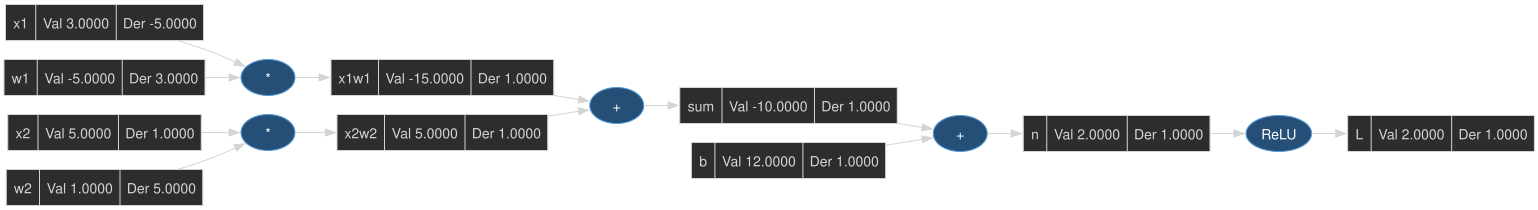

In [128]:
draw_graph(L, rankdir='LR')

In [127]:
L.backward()

In [133]:
x2.der

1.0

In [57]:
## What is derivative of L wrt n (node  that is made by ReLU)
## ReLU = if value is negative, then 0 or the value
## ReLU = max(0, x)
# Derivative of ReLU is output derivative times 1 (because value of x is x when x  > 0)
n.der = 1.0 # 

In [63]:
b.der = 1.0;  summation.der = 1.0
x1w1.der = 1.0; x2w2.der = 1.0
x1.der = x1w1.der * w1.value ; w1.der = x1w1.der * x1.value
x2.der = x2w2.der * w2.value ; w2.der = x2w2.der * x2.value

In [84]:
def temp():
    '''
    x1 = Scalar(3.0, 'x1')
    w1 = Scalar(-5.0,'w1')
    x2 = Scalar(5.0, 'x2')
    w2 = Scalar(1.0, 'w2')
    b = Scalar(12.0, 'b')
    '''
    x1 = torch.Tensor([3.0]).double(); x1.requires_grad = True; 
    x2 = torch.Tensor([5.0]).double(); x2.requires_grad = True; 
    w1 = torch.Tensor([-5.0]).double(); w1.requires_grad = True; 
    w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True; 
    b = torch.Tensor([12.0]).double(); b.requires_grad = True; 
    n = x1 * w1 + x2 * w2 + b
    n.retain_grad()
    L = torch.relu(n)
    L.retain_grad()

In [65]:
print(L.data.item())

2.0


In [66]:
L.backward() # We will implement this by hand!

In [67]:
L.grad.item()

1.0

In [69]:
n.grad.item()

1.0

In [70]:
x1.grad.item()

-5.0

In [71]:
w1.grad.item()

3.0

In [72]:
x2.grad.item()

1.0

In [73]:
w2.grad.item()

5.0

In [143]:
import random
random.random()


0.5288667616131593

In [150]:
random.uniform(-2,2)

1.3572662018179522

In [ ]:
import random
class Neuron:

    # CTOR
    # n_inputs = number of inputs
    def __init__(self, n_inputs)
        # we already have "Class Scalar" to capture numbers
        # So, use it to make weights
        self.weights = [Scalar(random.random()) for _ in range (n_inputs)]
        self.bias = Scalar(random.uniform(-1,1))

    # Meaning of "calling a neuron"

    '''

    z = Act (x1w1 + x2 w2 + .... + bias)

    def (X):

        sum (xi * wi for i in ....)
    
    '''


    

In [ ]:
n = Neuron (2)
x = [Scalar(3.0, 'x1'), Scalar(-4.5, 'x2')] # separate inputs from weights